# Task 3 analysis of integer membership experiments

Authors: Кожахмет Медетбек and Джазбаев Айбар. This notebook analyses the recorded 5 November 2026 run. It does not rerun the benchmark. The primary question is whether a prebuilt set reduces typical lookup time by more than 20% relative to a list at 10,000 keys and 50% hits, subject to correctness and allocation guardrails.

The repository contains the raw evidence, collection metadata and reusable processing and plotting modules. Run all cells in order from a fresh kernel. The fixed bootstrap seed is 42.

In [1]:
from pathlib import Path
import sys, json, hashlib, platform
import numpy as np
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd().resolve()
if not (ROOT / 'src/process_data.py').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src/process_data.py').exists(), 'Run from the repository or notebooks directory'
sys.path.insert(0, str(ROOT))
from src import process_data as proc
from src.visualize import make_figures
np.random.seed(42)
pd.set_option('display.max_columns', 12)
print('Analysis Python:', platform.python_version())
print('Bootstrap:', proc.BOOTSTRAPS, 'resamples; seed', proc.SEED)


Matplotlib is building the font cache; this may take a moment.


Analysis Python: 3.12.14
Bootstrap: 10000 resamples; seed 42


## Data ingestion and validation

Validate every expected condition, phase, method, seed and repeat against the frozen configuration. Check pairing hashes, method order, timestamps and the latency/throughput identities. A missing observation, duplicate or invalid value stops the analysis. Status and environment files describe the collection runtime separately from this analysis runtime.

In [2]:
raw, config, status = proc.load_raw(ROOT)
environment = json.loads((ROOT / 'data/provenance/environment.json').read_text())
display(raw.head(6))
display(raw.groupby(['phase', 'method']).size().rename('observations').to_frame())
print('Collection runtime:', environment['implementation'], environment['python'])
print('Reference version matched:', environment['runtime_matches_pin'])
print('Run status:', status['status'], '| workers:', status['workers'])


,timestamp_utc,phase,size,hit_rate,seed,method,...,mean_lookup_ns,throughput_ops_per_s,build_ns,peak_python_bytes,errors,workload_sha256
0,2026-11-05 18:14:14.630795+00:00,warmup,10000,0.0,117,list,...,30988.8541,3.226967e+04,17292,88960,0,7a462561e72a4d578ed9fae2530ff0714fc5d6985ef15a...
1,2026-11-05 18:14:14.941823+00:00,warmup,10000,0.0,117,set,...,12.4000,8.064516e+07,96708,655624,0,7a462561e72a4d578ed9fae2530ff0714fc5d6985ef15a...
2,2026-11-05 18:14:14.943015+00:00,warmup,10000,0.0,117,list,...,31267.7500,3.198183e+04,14708,88960,0,7a462561e72a4d578ed9fae2530ff0714fc5d6985ef15a...
3,2026-11-05 18:14:15.256277+00:00,warmup,10000,0.0,117,set,...,13.0375,7.670182e+07,105666,655624,0,7a462561e72a4d578ed9fae2530ff0714fc5d6985ef15a...
4,2026-11-05 18:14:15.257500+00:00,benchmark,10000,0.0,117,set,...,10.9208,9.156838e+07,90000,655624,0,7a462561e72a4d578ed9fae2530ff0714fc5d6985ef15a...
5,2026-11-05 18:14:15.258350+00:00,benchmark,10000,0.0,117,list,...,31776.5459,3.146975e+04,15084,88960,0,7a462561e72a4d578ed9fae2530ff0714fc5d6985ef15a...


observations
phase     method              
benchmark list            2160
          set             2160
warmup    list             540
          set              540

Collection runtime: CPython 3.12.14
Reference version matched: True
Run status: completed | workers: 270


## Warmup exclusion and non-destructive cleaning

Only rows labelled `warmup` are excluded from performance summaries. This is a prespecified phase rule, not a rule that removes slow observations after seeing results. The untimed correctness/allocation pass precedes warmup, so warmup is not an untouched cold start. We flag batch-average timings outside 1.5 IQR within each condition and method, but retain all evaluation observations. Failed-observation rates are guardrails, not per-query error probabilities.

In [3]:
data = proc.filter_and_flag(raw)
print('Loaded:', len(raw), '| excluded warmup:', int(raw.phase.eq('warmup').sum()), '| retained:', len(data))
cleaning = data.groupby(proc.GROUP).agg(observations=('errors','size'),
    failed_observations=('errors',lambda x: int(x.gt(0).sum())),
    outliers_retained=('outlier_iqr','sum'))
display(cleaning)
assert len(data) == 4320
assert int(raw.phase.eq('warmup').sum()) == 1080


Loaded: 5400 | excluded warmup: 1080 | retained: 4320


observations  failed_observations  outliers_retained
size  hit_rate method                                                      
100   0.0      list             240                    0                 29
               set              240                    0                 40
      0.5      list             240                    0                 13
               set              240                    0                 14
      1.0      list             240                    0                  4
               set              240                    0                 12
1000  0.0      list             240                    0                 16
               set              240                    0                 15
      0.5      list             240                    0                 13
               set              240                    0                  8
      1.0      list             240                    0                  2
               set              240                    0                  7
10000 0.0      list             240                    0                  9
               set              240                    0                  1
      0.5      list             240                    0                 15
               set              240                    0                  6
      1.0      list             240                    0                  5
               set              240                    0                  3

## Seed-level statistical aggregation

Each timed batch contains 1,000 queries repeated ten times. `mean_lookup_ns` is batch elapsed time divided by 10,000; it includes the Python loop and hit accumulation, and excludes construction, tracing and file I/O. First take the median of eight technical repeats per seed, then describe the 30 seed estimates per condition. Mean, sample SD, median, p25, p75, p95 and p99 below refer to those seed estimates; p95/p99 are **not individual-query tail latencies**.

The 95% confidence interval is the 2.5th to 97.5th percentile of 10,000 bootstrap medians, resampling 30 seeds with replacement. It is conditional on this host and collection run. Throughput is computed for each observation before seed aggregation; it is derived from the same timer.

In [4]:
raw, data, summary, seeds, paired, paired_summary, audit = proc.process(ROOT)
columns = proc.GROUP + ['seed_count', 'mean_lookup_ns_mean', 'mean_lookup_ns_sd',
    'mean_lookup_ns_median', 'mean_lookup_ns_p25', 'mean_lookup_ns_p75',
    'mean_lookup_ns_p95', 'mean_lookup_ns_p99', 'mean_lookup_ns_ci_low', 'mean_lookup_ns_ci_high']
display(summary[columns].round(3))
print('Saved CSV files under data/processed/')


,size,hit_rate,method,seed_count,mean_lookup_ns_mean,mean_lookup_ns_sd,...,mean_lookup_ns_p25,mean_lookup_ns_p75,mean_lookup_ns_p95,mean_lookup_ns_p99,mean_lookup_ns_ci_low,mean_lookup_ns_ci_high
0,100,0.0,list,30,303.244,2.419,...,302.251,303.350,305.280,312.411,302.346,303.174
1,100,0.0,set,30,11.562,0.096,...,11.523,11.555,11.662,11.939,11.527,11.545
2,100,0.5,list,30,238.412,4.011,...,236.182,239.747,246.850,249.879,236.742,239.075
3,100,0.5,set,30,24.869,0.496,...,24.584,24.961,25.614,26.523,24.636,24.927
4,100,1.0,list,30,167.037,2.827,...,165.420,168.945,170.819,171.749,166.212,168.605
5,100,1.0,set,30,21.004,0.192,...,20.902,21.107,21.307,21.432,20.923,21.081
6,1000,0.0,list,30,2875.491,8.991,...,2870.617,2879.656,2885.432,2903.143,2870.860,2878.219
7,1000,0.0,set,30,17.067,0.179,...,16.950,17.193,17.321,17.412,16.984,17.152
8,1000,0.5,list,30,2168.297,31.089,...,2154.861,2179.833,2197.145,2265.971,2157.310,2174.486
9,1000,0.5,set,30,25.381,0.424,...,25.139,25.601,26.133,26.617,25.178,25.514


Saved CSV files under data/processed/


## Paired comparison and primary hypothesis

For each seed, divide the list estimate by the set estimate for speedup and calculate `1 - set/list` for relative improvement. Resampling these paired estimates preserves the pairing. The prespecified one-sided sign test counts the seeds strictly above 20% improvement; ties count as failures. Only 10,000 keys and 50% hits is confirmatory. The other eight conditions are exploratory.

The exact test assumes the seeded workloads provide independent units conditional on this host. Shared hardware, temporal drift and the single run limit generalisation; the confidence intervals are not evidence of performance on other computers.

In [5]:
from src.benchmark import binomial_upper_tail
primary = paired.loc[paired['size'].eq(10000) & paired.hit_rate.eq(.5)]
primary_summary = paired_summary.loc[paired_summary['size'].eq(10000) & paired_summary.hit_rate.eq(.5)]
threshold = config['hypothesis']['minimum_relative_improvement']
k = int(primary.relative_improvement.gt(threshold).sum())
p = binomial_upper_tail(k, len(primary))
collection_summary = json.loads((ROOT / 'data/provenance/summary.json').read_text())
assert environment['runtime_matches_pin']
assert abs(p - collection_summary['analysis']['p_value_one_sided']) < 1e-15
display(primary_summary.round(6))
print('Seeds above 20% improvement:', k, '/', len(primary))
print('One-sided exact sign-test p:', p)
print('Recorded decision:', collection_summary['analysis']['practical_decision'])


,size,hit_rate,speedup_mean,speedup_sd,speedup_median,speedup_p25,...,relative_improvement_p25,relative_improvement_p75,relative_improvement_p95,relative_improvement_p99,relative_improvement_ci_low,relative_improvement_ci_high
7,10000,0.5,819.174862,16.759499,822.781847,803.332083,...,0.998755,0.998799,0.998812,0.998821,0.99877,0.998794


Seeds above 20% improvement: 30 / 30
One-sided exact sign-test p: 9.313225746154785e-10
Recorded decision: supports_H1_within_scope


## Guardrails

No erroneous or high-memory record is removed. The experiment requires zero correctness errors and traced allocation peaks at most 8 MiB. Allocation peaks describe an untimed Python allocation probe, not total process RAM. They are copied across the repeats of one method/seed and are not independent memory measurements.

In [6]:
display(summary[proc.GROUP + ['failed_observation_count', 'failed_observation_rate', 'max_peak_python_mib']])
print(json.dumps(audit, indent=2))
assert audit['guardrails_pass'] == collection_summary['guardrails_pass']


,size,hit_rate,method,failed_observation_count,failed_observation_rate,max_peak_python_mib
0,100,0.0,list,0,0.0,0.009308
1,100,0.0,set,0,0.0,0.016510
2,100,0.5,list,0,0.0,0.009308
3,100,0.5,set,0,0.0,0.016510
4,100,1.0,list,0,0.0,0.009308
5,100,1.0,set,0,0.0,0.016510
6,1000,0.0,list,0,0.0,0.016174
7,1000,0.0,set,0,0.0,0.039948
8,1000,0.5,list,0,0.0,0.016174
9,1000,0.5,set,0,0.0,0.039948


{
  "raw_rows": 5400,
  "warmup_rows": 1080,
  "benchmark_rows": 4320,
  "outlier_rows_retained": 212,
  "failed_benchmark_observations": 0,
  "failed_warmup_observations": 0,
  "max_peak_python_mib": 0.6252517700195312,
  "guardrails_pass": true,
  "bootstrap_seed": 42,
  "bootstrap_resamples": 10000,
  "statistical_unit": "one seeded workload; eight technical repeats aggregated by median",
  "raw_sha256": "577b240fbee8cd3100be0c800c5142fb3772ed64df06a6ab2c69d173ae0db069"
}


## Scientific visualization and export

Figure 1 uses key count as workload size, not service request rate. Both axes are logarithmic; error bars and bands show 95% seed-bootstrap intervals. Distinct colors, markers and line styles distinguish the methods. Figure 2 shows all 30 primary-condition seed estimates, boxes for p25-p75, whiskers within 1.5 IQR, and a separate black diamond with a 95% CI. Its two panels have **separate linear y-scales** to show within-method dispersion; use Figure 1 for magnitude comparison. Every figure is exported as vector PDF and 300 DPI PNG.

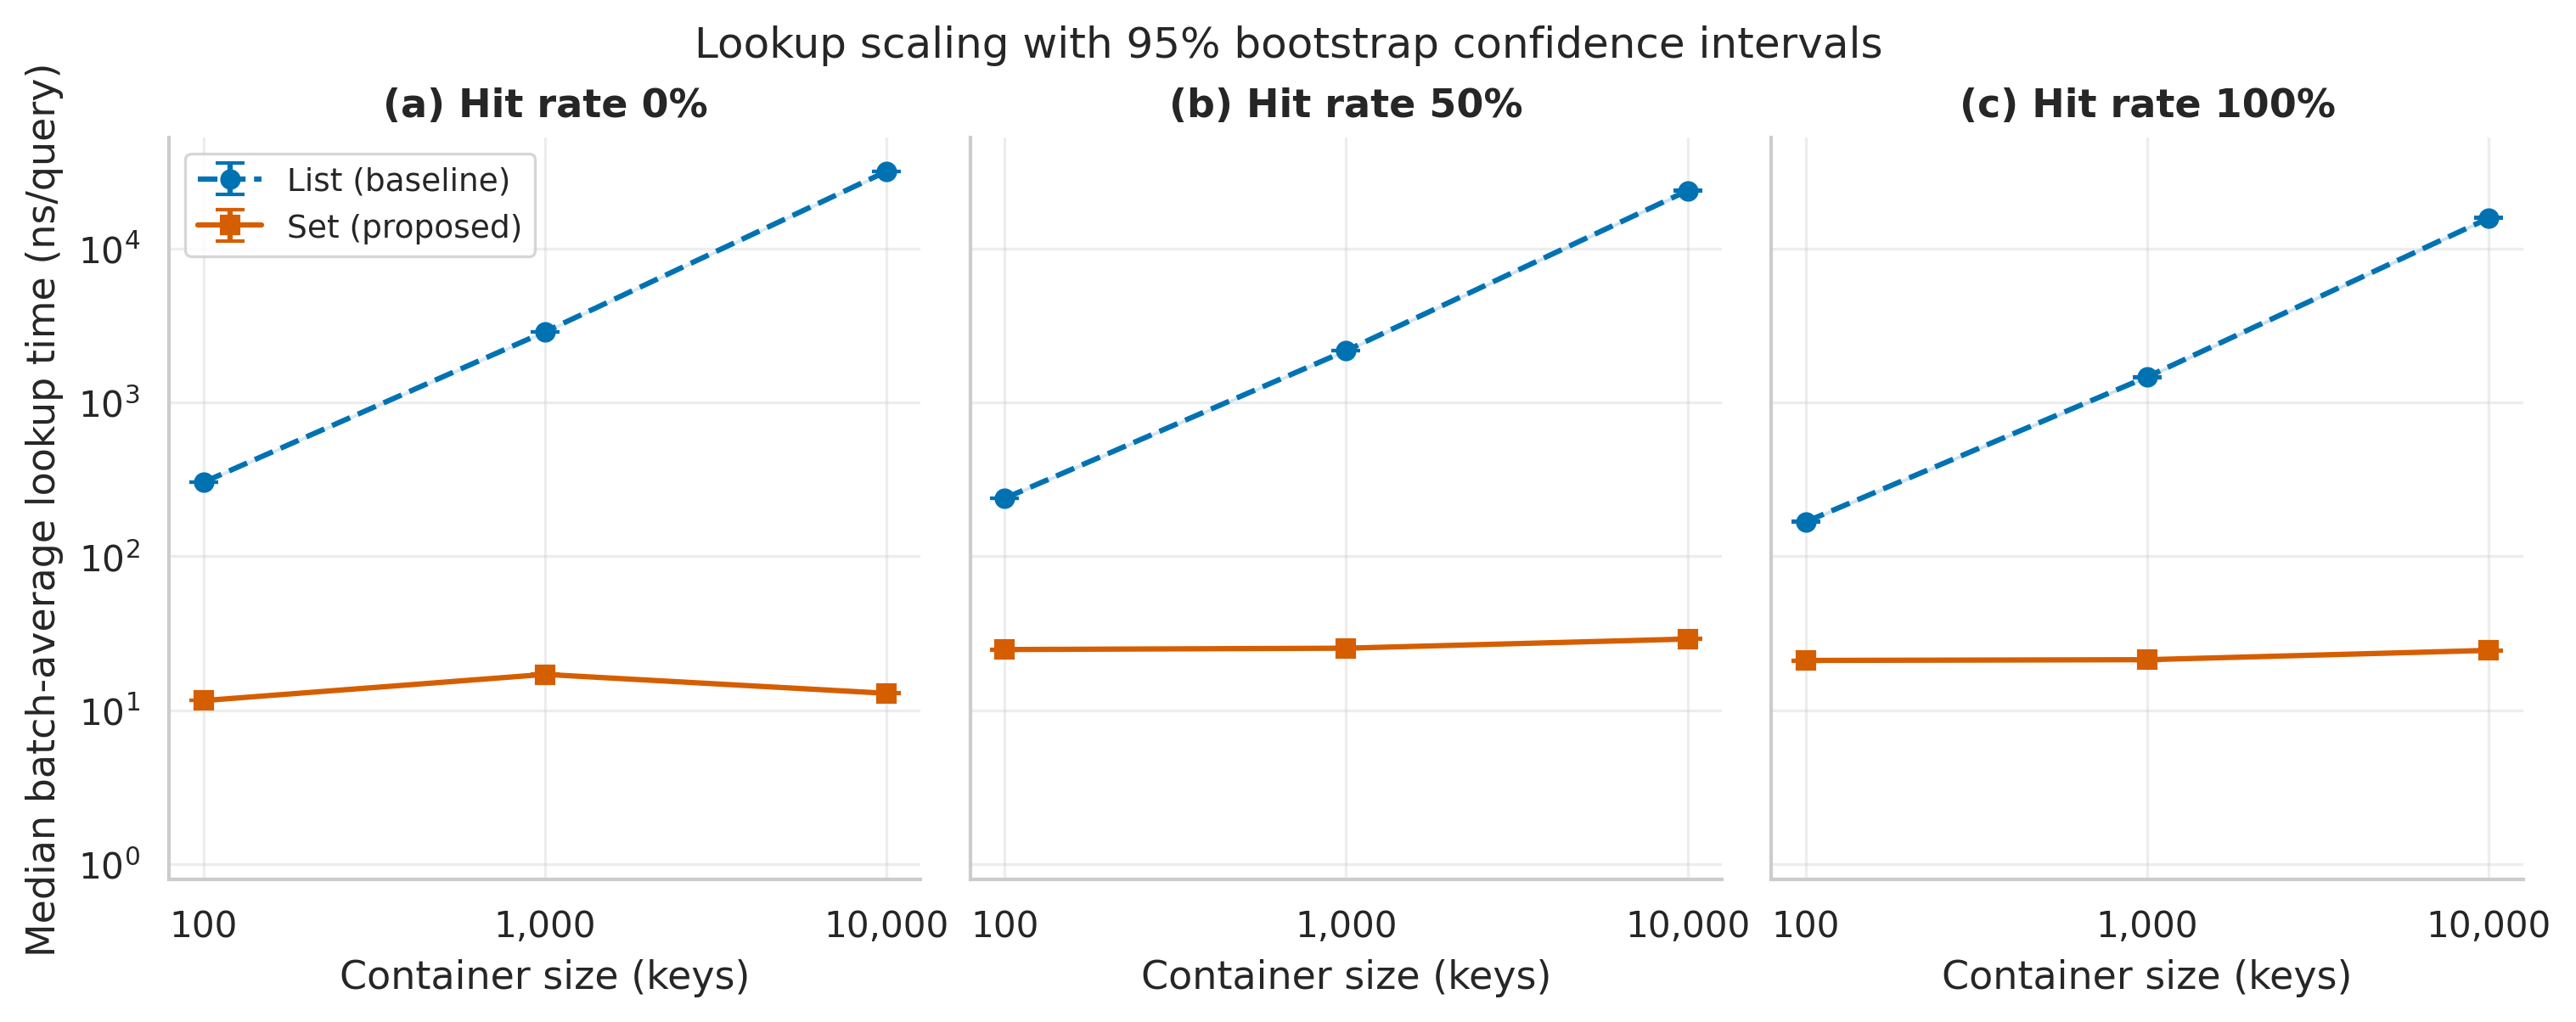

reports/figures/fig1_latency_vs_load.png and fig1_latency_vs_load.pdf


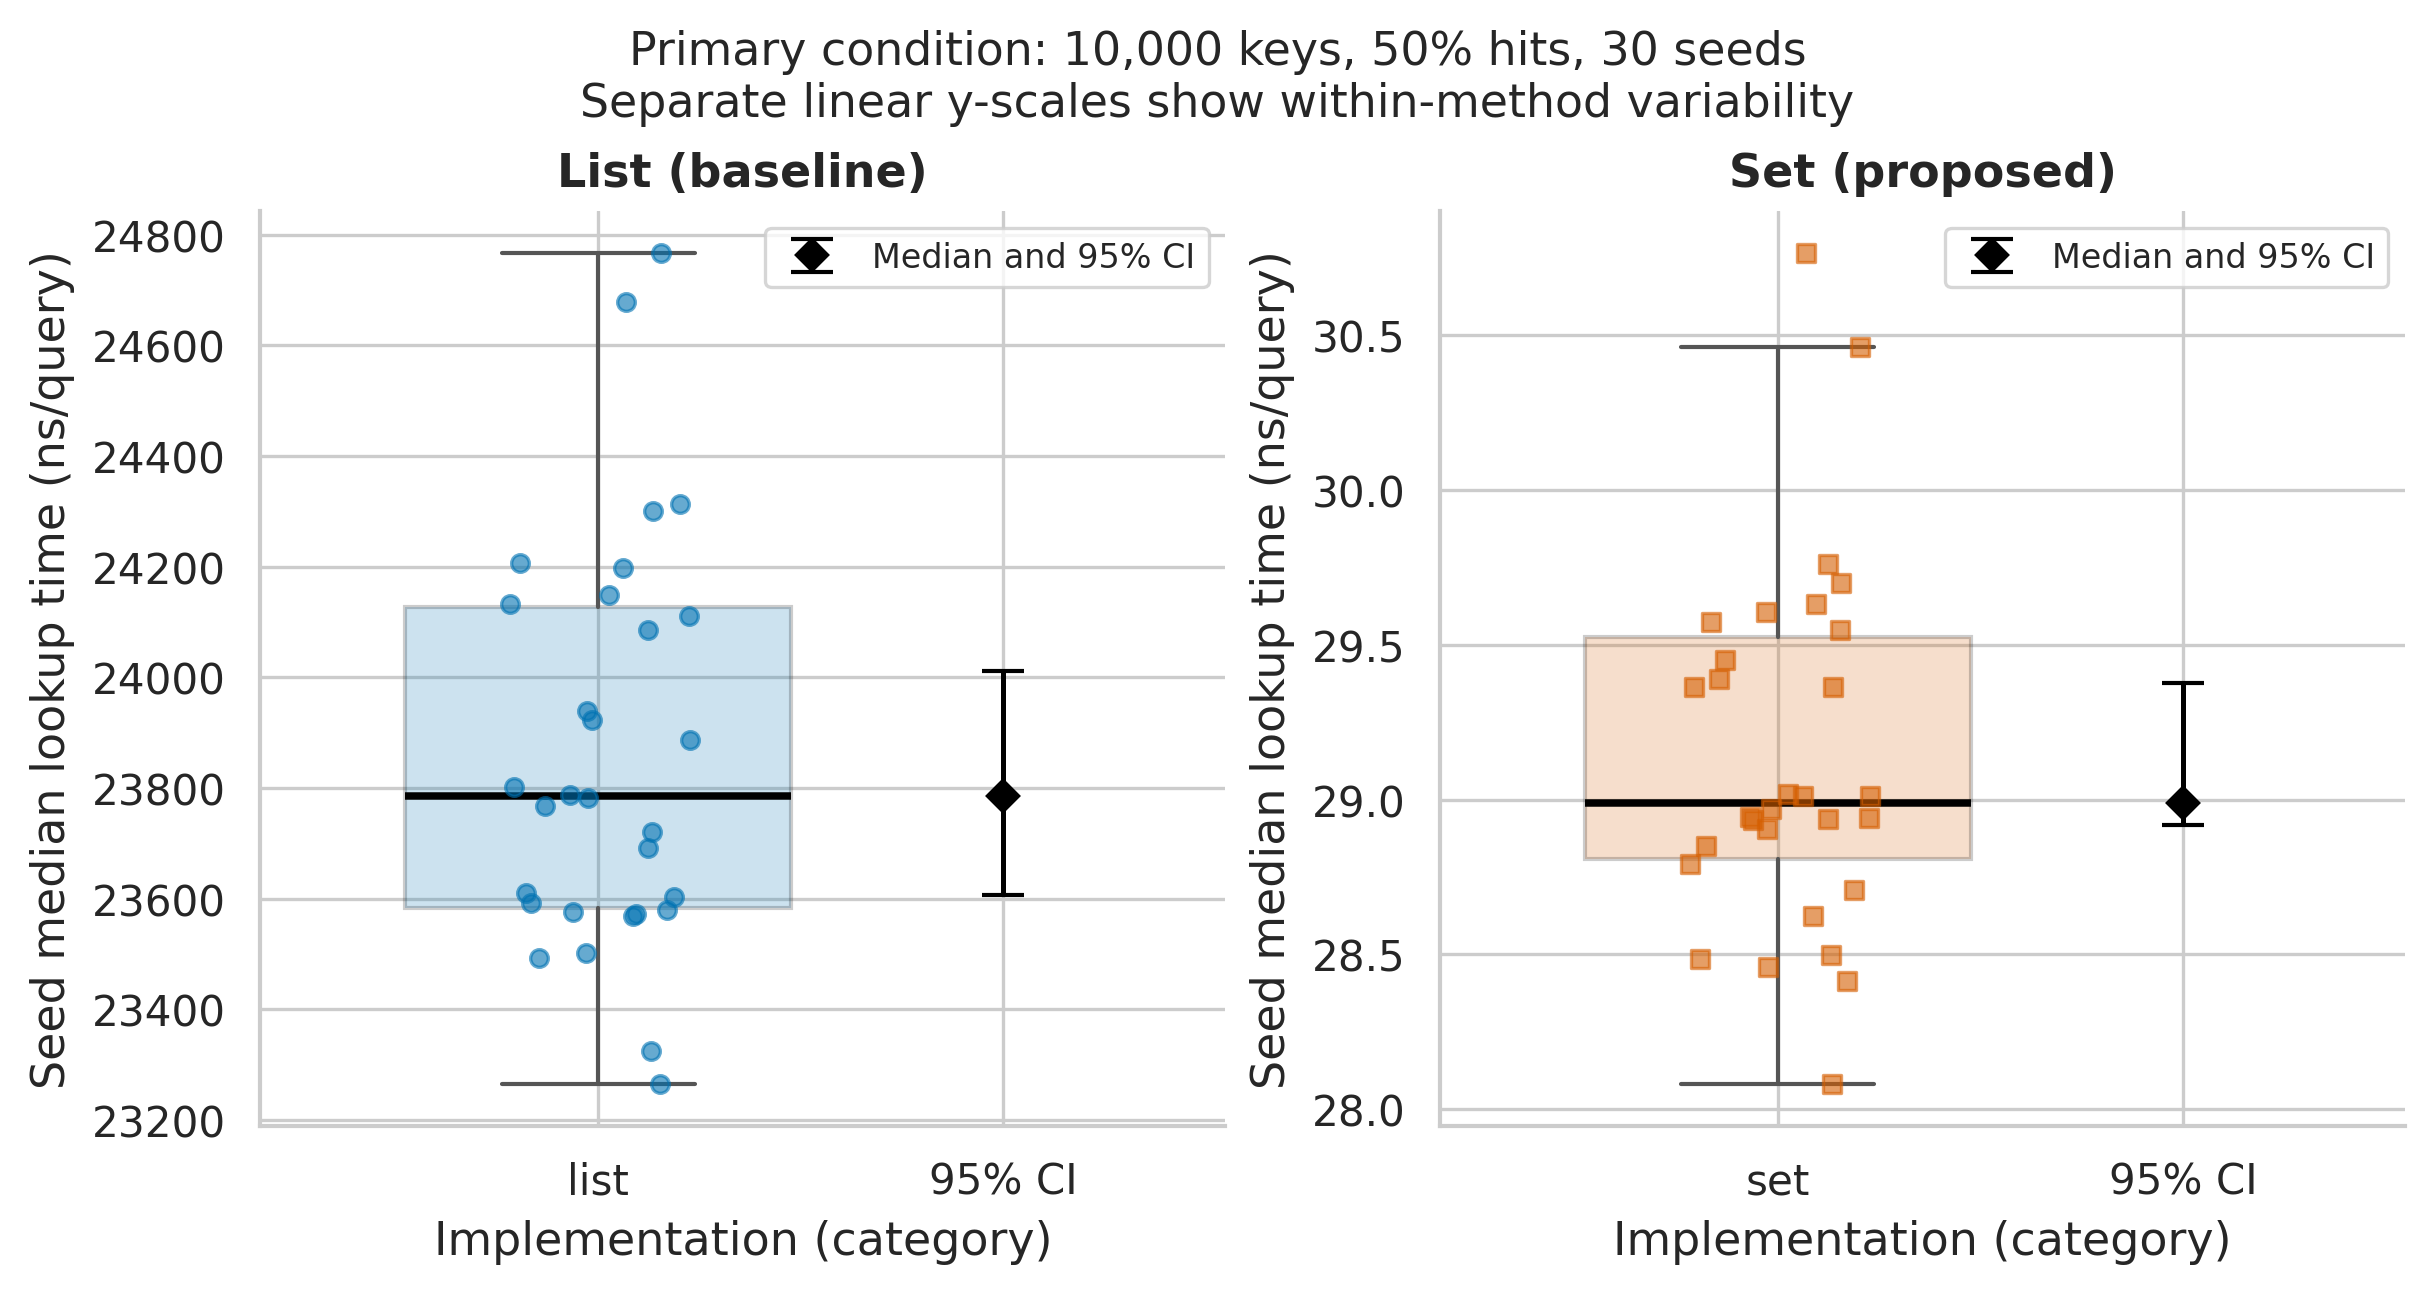

reports/figures/fig2_distribution_boxplot.png and fig2_distribution_boxplot.pdf


In [7]:
paths = make_figures(summary, seeds, ROOT / 'reports/figures')
for path in paths:
    display(Image(filename=str(path), width=950))
    print(path.relative_to(ROOT), 'and', path.with_suffix('.pdf').name)


## Interpretation and limitations

The comparison applies to repeated lookups in prebuilt containers with this integer workload. Set construction and higher allocation requirements matter for one-off queries. Uniform hits/misses, no adversarial collisions, one machine, fixed query count and a single native desktop run limit external validity. Background applications remained open; CPU affinity, frequency and thermal conditions were not controlled. Technical repeats do not increase the number of independent machines or runs.

The complete [C4 domain model](../docs/domain_model.md) identifies timing, allocation and correctness points. The [report](../reports/task3_report.md) provides the results and discussion. The next cell derives a compact conclusion from the measurements rather than hard-coding a speed claim.

In [8]:
row = primary_summary.iloc[0]
print(f"Primary median paired speedup: {row.speedup_median:.2f}x "
      f"(95% CI {row.speedup_ci_low:.2f} to {row.speedup_ci_high:.2f}).")
print(f"Median relative reduction: {100*row.relative_improvement_median:.3f}%.")
print(f"Guardrails passed: {audit['guardrails_pass']}.")
print('Inference is conditional on this host and protocol; no universal Python speedup is claimed.')
print('Input SHA256:', audit['raw_sha256'])


Primary median paired speedup: 822.78x (95% CI 812.66 to 829.02).
Median relative reduction: 99.878%.
Guardrails passed: True.
Inference is conditional on this host and protocol; no universal Python speedup is claimed.
Input SHA256: 577b240fbee8cd3100be0c800c5142fb3772ed64df06a6ab2c69d173ae0db069
